# 06 — Entraîner sur tout le corpus, et comparer au comptage

**Chapitre 1** · durée conseillée : 25 min · CPU uniquement (environ 2 min d'exécution)

![Parcours du chapitre](figures/00_parcours.svg)

Au notebook 05, nous avons fait **un pas** d'apprentissage sur les 5 bigrammes d'`emma`. Nous passons maintenant à **tous** les bigrammes de `names.txt`, et nous répétons le pas une centaine de fois.

![La boucle d'entraînement](figures/06_boucle.svg)

**La grande question de ce notebook :** partant d'une matrice aléatoire, et sans jamais voir la table `N`, la descente de gradient retrouve-t-elle les probabilités du comptage ?

In [1]:
# Préparation : imports et petit module partagé du chapitre
import math
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt

import bigramme  # fichier bigramme.py, à côté de ce notebook
from bigramme import SEED, plot_matrice_caracteres

words = bigramme.charger_prenoms()
chars, stoi, itos = bigramme.construire_vocabulaire(words)
print(f"{len(words):,} prénoms · vocabulaire de {len(stoi)} symboles · PyTorch {torch.__version__}")
from bigramme import forward_from_indices, nll_from_probs

N = bigramme.compter_bigrammes(words, stoi)
P = N.float() / N.sum(dim=1, keepdim=True)

32,033 prénoms · vocabulaire de 27 symboles · PyTorch 2.14.1+cu130


## 1. Tous les exemples du corpus

- `xs` : l'indice du caractère courant, pour **chaque** bigramme du corpus ;
- `ys` : l'indice du vrai caractère suivant ;
- `M = len(ys)` : le **nombre de transitions** (pas 27, pas le nombre de prénoms) ;
- `torch.arange(M)` : les `M` numéros de lignes, et `ys` les `M` colonnes à lire.

Une **seule ligne** calcule la probabilité de la bonne réponse pour chaque observation, exactement comme sur `emma` :

```python
loss = -probs[torch.arange(M), ys].log().mean()
```

In [2]:
xs, ys = bigramme.construire_exemples(words, stoi)
M = len(ys)
xenc = F.one_hot(xs, num_classes=27).float()

print(f"Prénoms : {len(words):,}  ·  transitions M : {M:,}")
print("xs :", tuple(xs.shape), "| ys :", tuple(ys.shape), "| xenc :", tuple(xenc.shape))
print("Les 5 premiers exemples :", [f"{itos[a]}→{itos[b]}" for a, b in zip(xs[:5].tolist(), ys[:5].tolist())])

loss_comptage = -P[xs, ys].log().mean().item()
print(f"\nRéférence à battre (ou égaler) : loss du comptage = {loss_comptage:.4f}")

Prénoms : 32,033  ·  transitions M : 228,146
xs : (228146,) | ys : (228146,) | xenc : (228146, 27)
Les 5 premiers exemples : ['.→e', 'e→m', 'm→m', 'm→a', 'a→.']

Référence à battre (ou égaler) : loss du comptage = 2.4540


## 2. La boucle d'entraînement

Chaque itération enchaîne les cinq étapes du notebook 05 :
1. **forward** : `W → logits → probabilités` ;
2. **loss** : une colonne par ligne, puis la NLL moyenne ;
3. **remise à zéro** : `W.grad = None` ;
4. **backward** : `loss.backward()` remplit `W.grad` ;
5. **mise à jour** : `W -= lr * W.grad` sous `torch.no_grad()`.

### Mini-expérience : seul le learning rate change

Pour une comparaison honnête, tous les essais partent **des mêmes 729 poids initiaux** et utilisent **les mêmes données**.

**Avant d'exécuter :** les quatre courbes suivront-elles la même trajectoire ? Laquelle s'approchera le plus du comptage ?

> **Nuance :** `lr = 50` convient ici parce que le modèle est minuscule et que la loss est une moyenne sur 228 000 exemples, donc ses gradients sont petits. Dans un Transformer, un tel pas serait catastrophique (au chapitre 2, on utilisera `1e-3` avec AdamW). Le learning rate dépend toujours du modèle et de l'optimiseur.

In [3]:
import time

initial_W = torch.randn((27, 27), generator=torch.Generator().manual_seed(SEED))


def train_bigram(learning_rate, steps=100, W_depart=None, reg=0.0):
    W = (initial_W if W_depart is None else W_depart).clone().detach().requires_grad_(True)
    history = []
    for step in range(steps):
        # (1) FORWARD : W -> logits -> probabilités
        logits = xenc @ W                                   # (M, 27)
        counts = logits.exp()                               # (M, 27)
        probs = counts / counts.sum(dim=1, keepdim=True)    # (M, 27)
        # (2) LOSS : une bonne colonne par ligne, puis la moyenne
        loss = -probs[torch.arange(M), ys].log().mean()     # scalaire
        history.append(loss.item())
        loss = loss + reg * (W ** 2).mean()                 # régularisation (section 5), nulle par défaut
        # (3) REMISE À ZÉRO
        W.grad = None
        # (4) BACKWARD : remplit W.grad, ne change pas W
        loss.backward()
        # (5) MISE À JOUR : maintenant seulement, on change les poids
        with torch.no_grad():
            W -= learning_rate * W.grad
    return W.detach(), history


experiments = {}
for rate in [0.1, 1.0, 10.0, 50.0]:
    t0 = time.time()
    experiments[rate] = train_bigram(rate, steps=100)
    h = experiments[rate][1]
    print(f"lr = {rate:>5} : loss {h[0]:.3f} → {h[-1]:.4f}   ({time.time() - t0:.1f} s)")

lr =   0.1 : loss 3.759 → 3.6733   (13.8 s)


lr =   1.0 : loss 3.759 → 3.1887   (12.6 s)


lr =  10.0 : loss 3.759 → 2.5764   (12.9 s)


lr =  50.0 : loss 3.759 → 2.4729   (13.0 s)


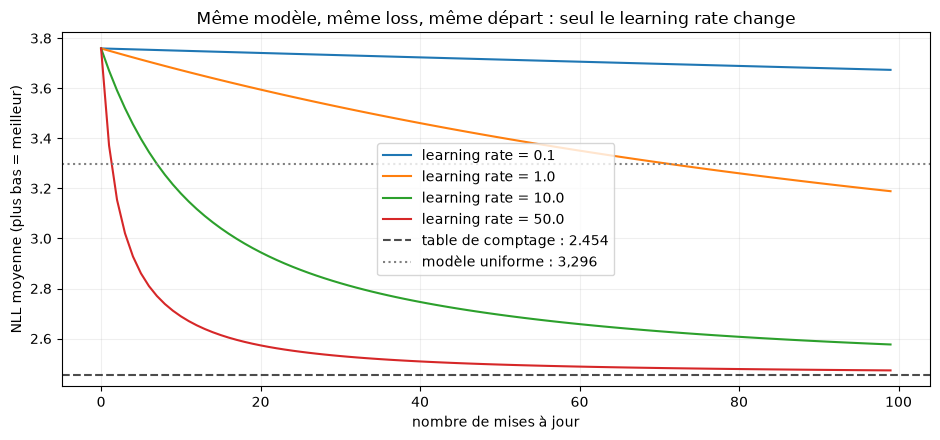

In [4]:
fig, ax = plt.subplots(figsize=(9.5, 4.5))
for rate, (_, history) in experiments.items():
    ax.plot(history, label=f"learning rate = {rate}")
ax.axhline(loss_comptage, color="black", linestyle="--", alpha=0.7, label=f"table de comptage : {loss_comptage:.3f}")
ax.axhline(math.log(27), color="gray", linestyle=":", label="modèle uniforme : 3,296")
ax.set(xlabel="nombre de mises à jour", ylabel="NLL moyenne (plus bas = meilleur)",
       title="Même modèle, même loss, même départ : seul le learning rate change")
ax.grid(alpha=0.2); ax.legend(); plt.tight_layout(); plt.show()

### Lire les courbes

**Ce que le graphique montre :** les quatre essais optimisent **la même loss** depuis **le même départ**. Avec `0.1`, on ne voit presque aucun progrès en 100 pas. Avec `50`, on arrive tout près du comptage.

On remarque aussi que la loss **de départ** (≈ 3,76) est **pire que l'uniforme** (3,30). Un `W` aléatoire n'est pas « neutre » : il a des préférences arbitraires, et elles sont fausses. On reviendra sur l'initialisation au chapitre 2.

**Ce que le graphique ne montre pas :** que les 27 probabilités de **chaque ligne** sont les mêmes que celles du comptage. Deux modèles peuvent avoir une loss proche sans avoir des tables identiques. Vérifions-le.

### Et si on continue ?

In [5]:
W_50, h_50 = experiments[50.0]
W_long, h_long = train_bigram(50.0, steps=300, W_depart=W_50)
print(f"Après 100 pas : {h_50[-1]:.4f}")
print(f"Après 400 pas : {h_long[-1]:.4f}")
print(f"Comptage      : {loss_comptage:.4f}")

Après 100 pas : 2.4729
Après 400 pas : 2.4578
Comptage      : 2.4540


## 3. Le réseau a-t-il retrouvé la table du comptage ?

![Deux chemins](figures/06_deux_chemins.svg)

On compare, pour un caractère courant fixé (`a`), **les 27 probabilités** :
- **comptage** : `P[stoi['a']]`, les proportions dans `names.txt` ;
- **réseau** : `softmax(W_trained[stoi['a']])`, les poids ajustés par gradient.

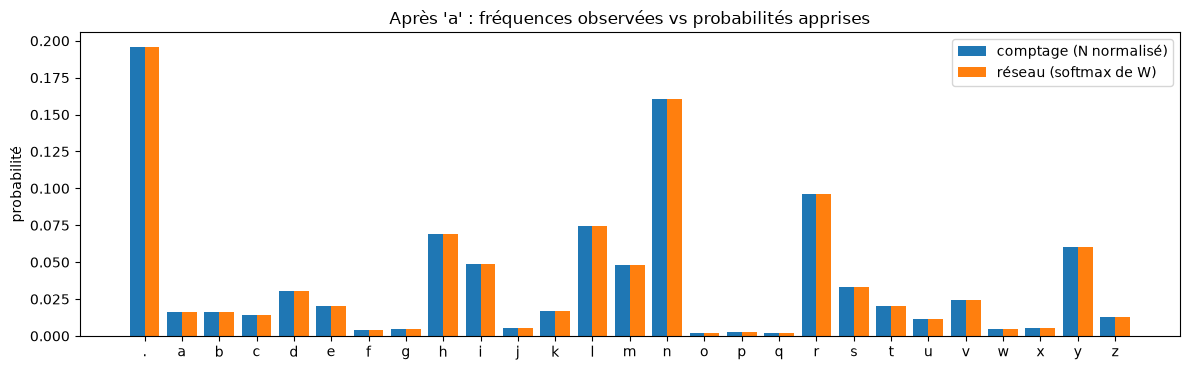

Loss : comptage 2.4540 · réseau 2.4578
Écart absolu moyen entre les deux tables : 0.00172


In [6]:
W_trained = W_long
with torch.no_grad():
    learned_probs = F.softmax(W_trained, dim=1)       # la « table » du réseau : une ligne par caractère

current_char = "a"            # essayez 'e', 'm', '.', 'q'…
i = stoi[current_char]
x = torch.arange(27).numpy()
fig, ax = plt.subplots(figsize=(12, 3.8))
ax.bar(x - .2, P[i].numpy(), width=.4, label="comptage (N normalisé)")
ax.bar(x + .2, learned_probs[i].numpy(), width=.4, label="réseau (softmax de W)")
ax.set_xticks(x, [itos[j] for j in range(27)])
ax.set(title=f"Après '{current_char}' : fréquences observées vs probabilités apprises", ylabel="probabilité")
ax.legend(); plt.tight_layout(); plt.show()

network_loss = -learned_probs[xs, ys].log().mean().item()
print(f"Loss : comptage {loss_comptage:.4f} · réseau {network_loss:.4f}")
print(f"Écart absolu moyen entre les deux tables : {(P - learned_probs).abs().mean().item():.5f}")

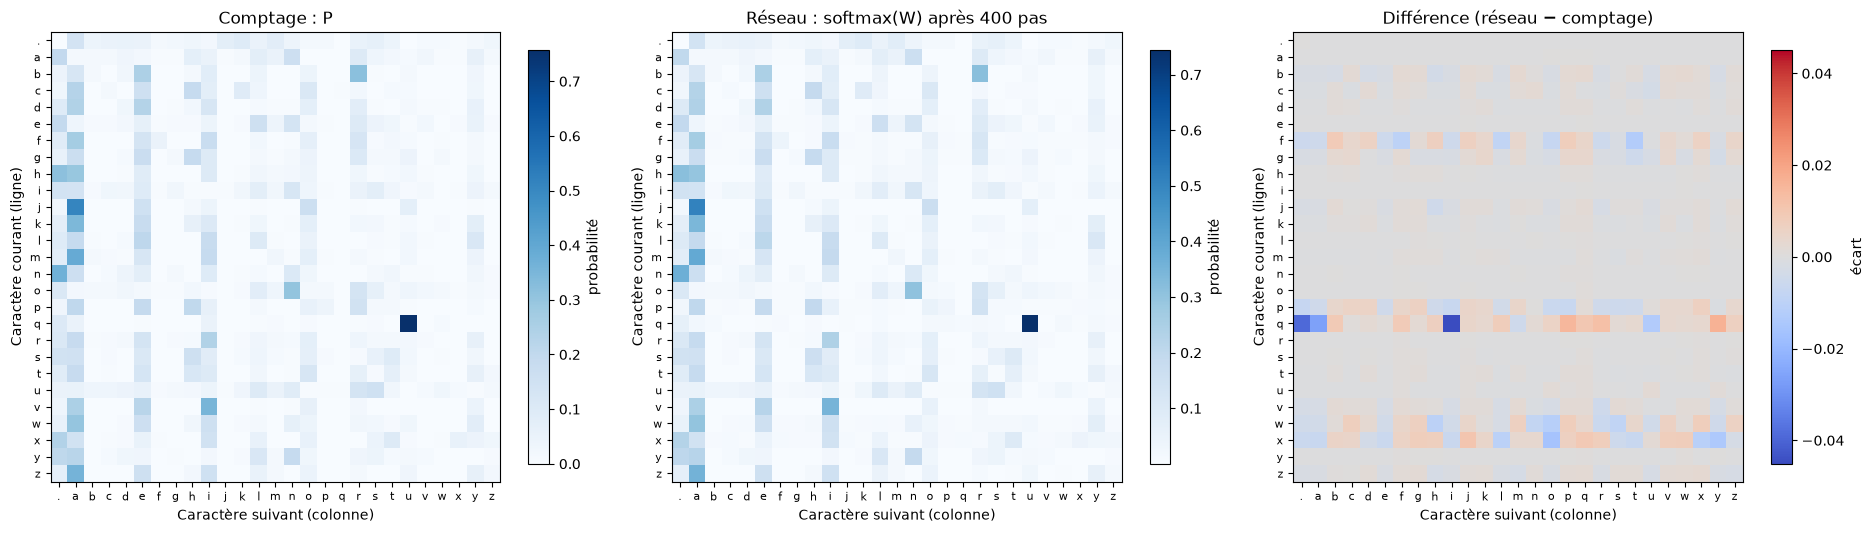

Lignes les moins observées : [('q', 272), ('x', 697), ('f', 905)]
Lignes les plus différentes : ['q', 'x', 'w']


In [7]:
fig, axes = plt.subplots(1, 3, figsize=(19, 5.5))
plot_matrice_caracteres(P, itos, title="Comptage : P", cbar_label="probabilité", ax=axes[0])
plot_matrice_caracteres(learned_probs, itos, title="Réseau : softmax(W) après 400 pas",
                        cbar_label="probabilité", ax=axes[1])
ecart = learned_probs - P
lim = ecart.abs().max().item()
plot_matrice_caracteres(ecart, itos, title="Différence (réseau − comptage)",
                        cbar_label="écart", cmap="coolwarm", ax=axes[2], vmin=-lim, vmax=lim)
plt.tight_layout(); plt.show()

lignes_rares = N.sum(dim=1).argsort()[:3]
ecart_par_ligne = (P - learned_probs).abs().sum(dim=1)
print("Lignes les moins observées :", [(itos[k.item()], N[k].sum().item()) for k in lignes_rares])
print("Lignes les plus différentes :", [itos[k.item()] for k in ecart_par_ligne.argsort(descending=True)[:3]])

**Que prouve cette comparaison ?** Les deux cartes sont presque indiscernables. Le réseau a **appris les fréquences des bigrammes** à partir de la seule loss : il n'a jamais vu `N`. Ce n'est pas une mémoire des prénoms : le modèle ne conserve que le dernier caractère.

**Nuances :**
- une transition **jamais observée** a une probabilité 0 dans la table, alors qu'un softmax de poids finis donne toujours une probabilité **strictement positive**. On parle donc de distributions **proches**, pas égales ;
- les lignes rarement observées convergent plus lentement : peu d'exemples, donc peu de gradient.

## 4. Générer avec le réseau entraîné

Aucune nouvelle logique n'est nécessaire : `learned_probs` est une table de probabilités, comme `P`. On réutilise **la même fonction** de génération qu'au notebook 01, avec la même graine.

In [8]:
print("Comptage :", bigramme.generer_prenoms(P, itos, n=10, seed=42))
print("Réseau   :", bigramme.generer_prenoms(learned_probs, itos, n=10, seed=42))

Comptage : ['anugeenvi', 's', 'mabian', 'dan', 'stan', 'silaylelaremah', 'li', 'le', 'epiachalen', 'diza']
Réseau   : ['anugeenvi', 's', 'mabian', 'dan', 'stan', 'silaylelaremah', 'li', 'le', 'epiachalen', 'diza']


Avec la même graine, les deux modèles produisent **les mêmes prénoms**. C'est une preuve très concrète que les deux tables sont proches : chaque tirage tombe dans le même caractère. Des différences finiraient par apparaître en générant davantage, quand un tirage tombe tout près de la frontière entre deux caractères.

## 5. Pour aller plus loin : la régularisation, cousine du lissage

Au notebook 02, ajouter de faux comptages (`N + k`) rapprochait chaque ligne de l'uniforme. Pour le réseau, l'équivalent consiste à **pousser les poids vers 0**. Si tous les logits d'une ligne sont égaux, le softmax est uniforme. On ajoute donc à la loss une pénalité `reg × moyenne(W²)` :

$$
\mathcal L_\text{total} = \text{NLL} + \lambda\cdot\overline{W^2}.
$$

Plus $\lambda$ est grand, plus les distributions sont « lissées ». Au chapitre 2, le *weight decay* d'AdamW joue ce rôle.

In [9]:
for reg in [0.0, 0.1, 1.0]:
    W_r, h_r = train_bigram(50.0, steps=100, reg=reg)
    p_r = F.softmax(W_r, dim=1)
    print(f"λ = {reg:<4} : NLL = {h_r[-1]:.4f} · probabilité minimale de la table = {p_r.min().item():.1e}"
          f" · max |W| = {W_r.abs().max().item():.2f}")

λ = 0.0  : NLL = 2.4729 · probabilité minimale de la table = 9.8e-04 · max |W| = 3.97


λ = 0.1  : NLL = 2.5055 · probabilité minimale de la table = 3.8e-03 · max |W| = 3.26


λ = 1.0  : NLL = 2.7213 · probabilité minimale de la table = 1.4e-02 · max |W| = 2.43


La régularisation fait un peu remonter la NLL sur le corpus, mais elle **garde les poids plus petits** (max |W| passe d'environ 4 à 2,4). Elle évite aussi les probabilités quasi nulles. C'est exactement le compromis du lissage : on accepte d'être un peu moins collé aux données pour être moins catégorique.

## Synthèse : à savoir expliquer sans regarder le code

| | modèle par comptage | modèle neuronal |
|---|---|---|
| formule | $P_{ij}=\dfrac{N_{ij}}{\sum_k N_{ik}}$ | $P_{ij}(W)=\dfrac{e^{W_{ij}}}{\sum_k e^{W_{ik}}}$ |
| obtenu par | un calcul direct | la minimisation de la NLL par gradient |
| paramètres | 729 compteurs | 729 poids |
| loss sur `names.txt` | 2,454 | ≈ 2,46 après 400 pas |
| zéros | oui (sauf lissage) | jamais (softmax) |
| lissage | `N + k` | régularisation `λ·W²` |

**Les quatre invariants pour toute la suite du cours :**
1. le modèle produit des **logits** ;
2. le **softmax** les transforme en probabilités ;
3. la **NLL moyenne** mesure les erreurs de prédiction ;
4. la **descente de gradient** ajuste les poids pour la faire baisser.

Ces quatre lignes resteront **exactement** les mêmes pour le Transformer du chapitre 2. Seule change la façon de calculer les logits.

**Retour à la question d'ouverture :** pourquoi apprendre une table qu'on sait calculer ? Parce que le comptage **ne passe pas à l'échelle**. Avec un contexte de 8 caractères, il faudrait $27^8 \approx 2{,}8 \times 10^{11}$ lignes, presque toutes vides. Un réseau, lui, peut **partager** ce qu'il apprend entre contextes semblables. C'est l'objet du chapitre 2 : plus de contexte, sans tout compter.

## Annexe — Vérification individuelle (après le cours)

Sans exécuter de code :
1. Pourquoi `P[stoi['a']]` contient-il 27 valeurs de somme 1 ?
2. Quelle est la forme de `xenc @ W` pour un lot de 200 bigrammes ?
3. Pourquoi la NLL explose-t-elle quand le modèle donne une probabilité minuscule à la bonne réponse ?
4. Pourquoi la mise à jour suit-elle `−W.grad` et non `+W.grad` ?
5. Pourquoi le gradient de la ligne `q` de `W` est-il nul quand on s'entraîne seulement sur `emma` ?
6. Quelle limite du bigramme le chapitre 2 va-t-il lever ?

**Petit défi de code :** changez `current_char` en `e`, `m`, `.` ou `q` dans la comparaison. Quelles lignes sont les mieux apprises ? Pourquoi ?

## Références
- Andrej Karpathy, [*The spelled-out intro to language modeling: building makemore*](https://www.youtube.com/watch?v=PaCmpygFfXo) (2022) et le dépôt [makemore](https://github.com/karpathy/makemore), dont viennent `names.txt` et l'esprit de ce chapitre (la boucle d'entraînement, la comparaison avec le comptage et la régularisation suivent sa présentation).
- Y. Bengio et al., [*A Neural Probabilistic Language Model*](https://www.jmlr.org/papers/volume3/bengio03a/bengio03a.pdf), JMLR 2003 : pourquoi les paramètres partagés battent le comptage quand le contexte grandit.
- I. Goodfellow, Y. Bengio et A. Courville, [*Deep Learning*](https://www.deeplearningbook.org/), 2016, section 7.1 (pénalité L2 = *weight decay*).
- D. Jurafsky et J. H. Martin, [*Speech and Language Processing*](https://web.stanford.edu/~jurafsky/slp3/), chapitre 3 (lissage) et chapitre 7 (modèles de langage neuronaux).